<!-- gs-watermark -->
> **© 2026 Gokaran Shukla** · part of [orchid](https://github.com/Gokaran-Shukla/orchid) · MIT License — any reuse must keep this copyright notice and credit the author.

# ORCHID tutorial 13: Benchmarking and validation

**Goals.** Understand how ORCHID is validated (V1–V27), read the benchmark report, and re-run any
benchmark yourself.

The suite has three kinds of checks:
* **Exact limits:** detailed balance, Madelung constant, Airy formula, $\eta=k_r/(k_r+k_{nr})$, exciton bookkeeping.
* **Published results:** Pasveer EGDM, Koster $V_{oc}$, Mott–Gurney, Juška CELIV, Martens $\tfrac34C_{geo}$, the gradual channel.
* **Other codes:** NIST Sesame (drift–diffusion) and `tmm` (optics), compared on identical inputs.

The tolerances in `validation/criteria.py` are fixed in advance.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.figsize": (5.4, 3.6), "axes.grid": True, "grid.alpha": 0.3})
import orchid
print("ORCHID", orchid.__version__)

ORCHID 0.4.0


In [2]:
import os, sys
root = os.path.abspath(os.path.join(os.getcwd(), "..", ".."))
sys.path.insert(0, os.path.join(root, "validation"))
from criteria import evaluate
rows = evaluate()
for r in rows:
    st = {True: "PASS", False: "FAIL", None: "INFO"}[r["passed"]]
    print(f"{r['id']:>4} {st}  {r['what']:<32} {r['value'][:70]}")
print(sum(r["passed"] is True for r in rows), "/", sum(r["passed"] is not None for r in rows), "pass")

  V1 PASS  mu(T), p->0                      ME vs KMC 2.8 %; ME/EGDM <= 1.30 (s<=3)
  V2 PASS  mu(p)                            g1 monotone: True; EGDM within x1.50 (s=3,4)
  V3 PASS  mu(F)                            field enhancement monotone in F: True
  V4 PASS  <E>_inf                          1.7 % from -sigma^2/kT at s=2
  V5 PASS  SCLC                             J/J_MG -> 1.065
  V6 PASS  Voc(G)                           max |dVoc| 1.34 mV; slope 1.0040 kT/e
  V7 PASS  exciton D                        |D_KMC - D_exact| = 1.37 sigma
  V8 PASS  optics                           Airy 2.8e-16; R+T+A 7.1e-06
  V9 PASS  inverse problems                 GDM params within 0.93 %; DD mu within 0.023 dec
 V10 PASS  TOF transients                   t_transit grows with sigma-hat: True
 V11 PASS  Marcus vs MA                     detailed balance 7.1e-15
 V12 PASS  OLED / OPV                       roll-off and TTA ordering: True; Braun PCE < free: True
 V13 PASS  3D device KMC               

Re-run from a terminal:

```bash
python validation/run_all.py --run          # everything (about an hour on 2 cores)
python validation/run_all.py --run V24 V25  # selected benchmarks
orchid bench                                # evaluate existing results
```

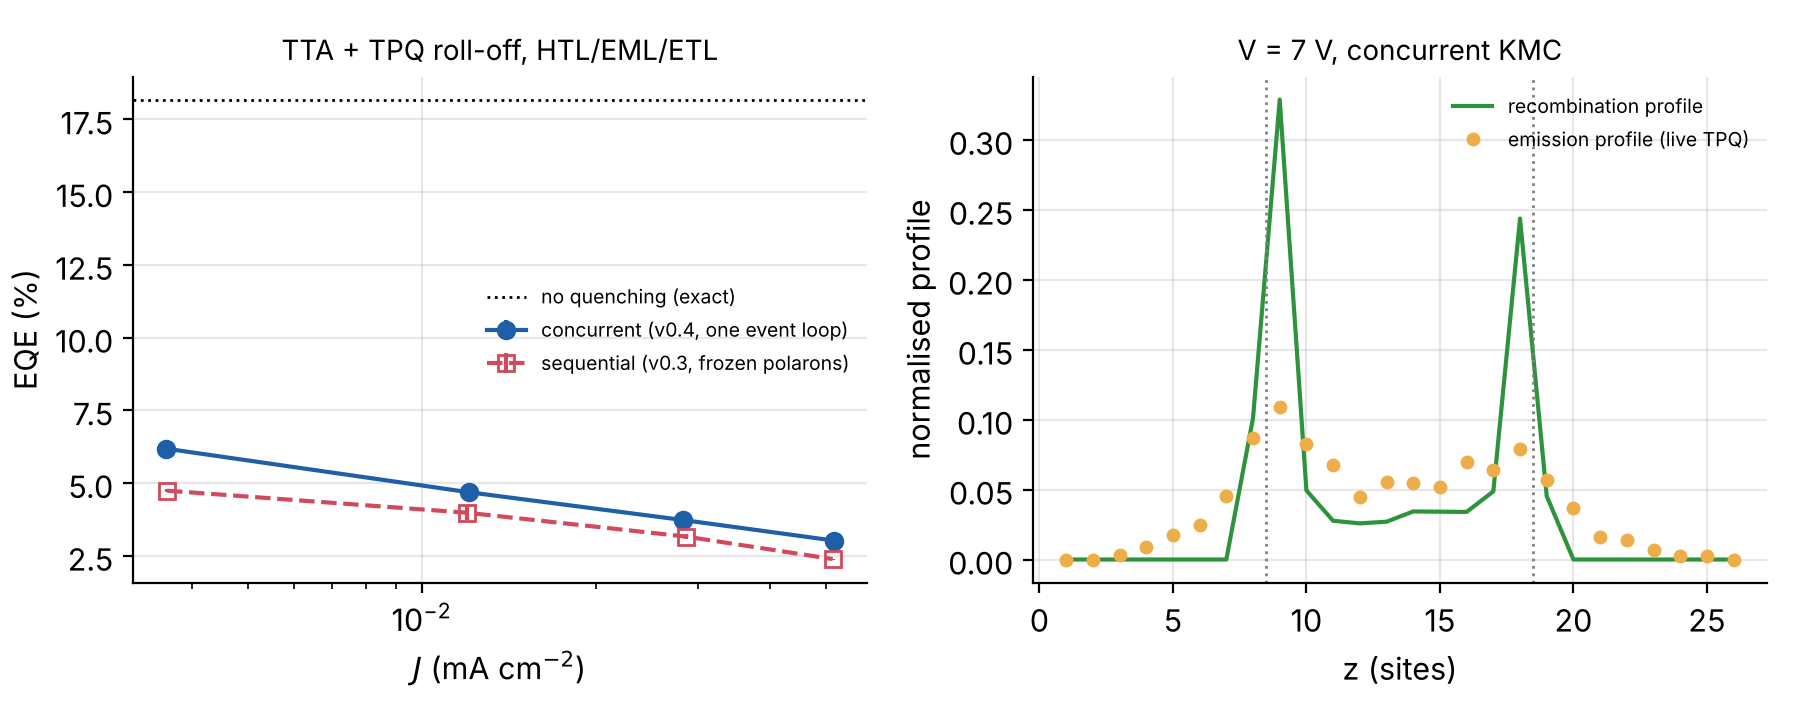

In [3]:
from IPython.display import Image, display
fig = os.path.join(root, "validation", "figures", "v24_coupled.png")
if os.path.exists(fig):
    display(Image(fig, width=700))

**Exercise.** A KMC estimate gives $\eta=0.897\pm0.008$ against an exact 0.909. Is this a pass under a 3σ criterion?

<details><summary>Solution</summary>

$z=(0.897-0.909)/0.008=-1.5$, so $|z|<3$ and it passes.
</details>

## Quiz

Five questions on this section. Run the cell to see them, then grade yourself with
`quiz("13", answers="abcda")` (one letter per question). The same quiz runs in a terminal
with `orchid quiz 13`.

In [4]:
from orchid.tutorials import quiz
quiz("13")

Quiz 13: Benchmarking and validation

Q1. Why does V15 compare against NIST Sesame on identical grids?
    (a) Identical inputs isolate the equations and discretisation, so agreement to 1e-6 shows both codes solve the same problem
    (b) To test optics
    (c) Sesame is faster
    (d) To compare speed

Q2. When a benchmark fails, what does validation/criteria.py say to do?
    (a) Fix the code; tolerances are set in advance
    (b) Loosen the tolerance
    (c) Delete the benchmark
    (d) Change the reference

Q3. How should a stochastic KMC result be compared to an exact value?
    (a) By a z-score: |x - x_exact| / sigma_stat <= 3
    (b) It must be exactly equal
    (c) By visual inspection
    (d) Only the sign matters

Q4. V27 records events per second and solve times. What is it for?
    (a) Choosing the GPU
    (b) Comparing with other codes' papers
    (c) Pass/fail validation
    (d) Detecting performance regressions on the same machine across versions

Q5. Which command re-ru

In [5]:
# replace with your answers, e.g. "abcda"
# quiz("13", answers=".....")

<details><summary>Answer key</summary>

`aaadd`. Run `quiz("13", answers="aaadd")` to see the explanation for every question.
</details>

---
[Tutorial index](README.md) · ORCHID documentation · `orchid tutorials`